
---
date: "2026-10-25"
date-modified: last-modified
format:
  html:
    toc: true
---


# The Equational Form of a Linear Program

**Prerequisites:** [Linear Programs](linear-programs.ipynb) · [Polyhedra and Polytopes](polyhedra-and-polytopes.ipynb) · [Rank–Nullity](kernel-image-and-rank-nullity.ipynb#thm-rank-nullity)

## 1\. Equational Form

::: {#def-equational-form}
## Equational Form

An LP is in **equational form** if it reads
$$
\text{maximize } c^{\mathsf T}x \quad \text{subject to } Ax = b,\ x \ge 0,
$$
with $A \in \mathbb{R}^{m \times n}$, $b \in \mathbb{R}^m$, $c \in \mathbb{R}^n$. All constraints are equations, except the **sign constraints** $x_j \ge 0$.
:::

::: {#thm-equational-form-conversion}
## Every LP Can Be Brought to Equational Form

Starting from a maximization LP in variables $x_1, \dots, x_n$ (replace "minimize $c^{\mathsf T}x$" by "maximize $-c^{\mathsf T}x$" first), apply:

1. replace each constraint $a^{\mathsf T}x \le \beta$ by $a^{\mathsf T}x + s = \beta$, and each $a^{\mathsf T}x \ge \beta$ by $a^{\mathsf T}x - s = \beta$, with a new **slack variable** $s \ge 0$;
2. replace each variable $x_j$ without the sign constraint $x_j \ge 0$ by $y_j - z_j$ with new variables $y_j, z_j \ge 0$ (in the constraints and in the objective).

The result is an LP in equational form. Let $\varphi$ map a vector of the new variables to the vector $x$ with $x_j = y_j - z_j$ for the replaced variables and $x_j$ unchanged otherwise (slacks are forgotten). Then $\varphi$ maps the feasible set of the new LP **onto** the feasible set of the old one and preserves the objective value. Consequently the two LPs are both infeasible, both unbounded, or both have optimal solutions with the same optimal value; $\varphi$ maps optimal solutions to optimal solutions, and every optimal solution of the old LP is the image of an optimal solution of the new one.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-equational-form-conversion
Write $x'$ for a vector of new variables. The objective of the new LP is defined by substituting $x = \varphi(x')$ into $c^{\mathsf T}x$ (slack variables get coefficient $0$), so the values agree by construction.

*Feasible goes to feasible.* Let $x'$ be feasible for the new LP and $x = \varphi(x')$. A constraint $a^{\mathsf T}x + s = \beta$ with $s \ge 0$ gives $a^{\mathsf T}x = \beta - s \le \beta$; similarly for $\ge$; equations are unchanged; and the variables that kept their sign constraint are still $\ge 0$.

*Onto.* Let $x$ be feasible for the old LP. Put $y_j = x_j^+ = \max(x_j, 0)$, $z_j = x_j^- = \max(-x_j, 0)$ for the replaced variables, so $y_j, z_j \ge 0$ and $y_j - z_j = x_j$; and give each slack the value $s = \beta - a^{\mathsf T}x \ge 0$ (respectively $a^{\mathsf T}x - \beta \ge 0$). This $x'$ is feasible for the new LP and $\varphi(x') = x$.

*Consequences.* The two LPs have the same set of objective values on their feasible sets, since $\varphi$ is onto and value-preserving. Hence both are infeasible or both are feasible; the objective is unbounded above on one iff on the other; and the suprema agree. If $x'$ is optimal for the new LP, then every feasible $x$ of the old LP is $x = \varphi(\tilde x')$ for a feasible $\tilde x'$, and $c^{\mathsf T}x$ equals the value of $\tilde x'$, which is at most the value of $x'$, which equals $c^{\mathsf T}\varphi(x')$; so $\varphi(x')$ is optimal. If $x$ is optimal for the old LP, any $x'$ with $\varphi(x') = x$ (constructed above) has the largest value, so it is optimal. $\blacksquare$
:::

::: {#exm-conversion}
## A Conversion

$$
\text{maximize } 3x_1 - 2x_2 \quad \text{subject to } 2x_1 - x_2 \le 4,\quad x_1 + 3x_2 \ge 5,\quad x_2 \ge 0 .
$$
The variable $x_1$ is free; write $x_1 = y_1 - z_1$. Add slacks $s_1, s_2 \ge 0$. With the new variables ordered $(y_1, z_1, x_2, s_1, s_2)$ we get
$$
\text{maximize } 3y_1 - 3z_1 - 2x_2 \quad \text{s.t. } \begin{pmatrix} 2 & -2 & -1 & 1 & 0 \\ 1 & -1 & 3 & 0 & -1 \end{pmatrix}\begin{pmatrix} y_1 \\ z_1 \\ x_2 \\ s_1 \\ s_2 \end{pmatrix} = \begin{pmatrix} 4 \\ 5 \end{pmatrix}, \quad y_1, z_1, x_2, s_1, s_2 \ge 0 .
$$
Both LPs have optimal value $\frac{39}{7}$; the original optimum is $x = \big(\tfrac{17}7, \tfrac67\big)$.
:::

::: {.callout-tip collapse="true"}
## Proof of the optimum in @exm-conversion
From the two constraints, $x_1 \le 2 + \frac{x_2}2$ and $x_1 \ge 5 - 3x_2$, so $5 - 3x_2 \le 2 + \frac{x_2}2$, i.e. $x_2 \ge \frac67$. Then $3x_1 - 2x_2 \le 6 + \frac32x_2 - 2x_2 = 6 - \frac{x_2}2 \le 6 - \frac37 = \frac{39}7$. Equality requires $x_2 = \frac67$ and $x_1 = 2 + \frac37 = \frac{17}7$, which is feasible ($\frac{17}7 + \frac{18}7 = 5$). $\blacksquare$
:::

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID, FAINT = "#0b0b0b", "#52514e", "#d9d8d4", "#a3a29a"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})
from scipy.optimize import linprog

orig = linprog([-3, 2], A_ub=[[2, -1], [-1, -3]], b_ub=[4, -5], bounds=[(None, None), (0, None)])
A = np.array([[2, -2, -1, 1, 0], [1, -1, 3, 0, -1]], float); b = np.array([4, 5], float)
c = np.array([3, -3, -2, 0, 0], float)
eq = linprog(-c, A_eq=A, b_eq=b, bounds=[(0, None)] * 5)
y1, z1, x2, s1, s2 = eq.x
print("original:  value", round(-orig.fun, 6), "at x =", orig.x.round(6), " (39/7 =", round(39 / 7, 6), ")")
print("equational: value", round(-eq.fun, 6), "| phi(x') = (y1 - z1, x2) =", np.round([y1 - z1, x2], 6),
      "| slacks", np.round([s1, s2], 6))

original:  value 5.571429 at x = [2.428571 0.857143]  (39/7 = 5.571429 )
equational: value 5.571429 | phi(x') = (y1 - z1, x2) = [2.428571 0.857143] | slacks [0. 0.]



## 2\. Geometric Meaning

The feasible set of an LP in equational form is
$$
P = \{x : Ax = b\} \cap \{x : x \ge 0\},
$$
the intersection of an affine subspace with the nonnegative orthant $\mathbb{R}^n_{\ge 0}$. If $\operatorname{rank} A = m$ and $Ax = b$ has a solution $x_0$, then $\{Ax = b\} = x_0 + \ker A$ has dimension $n - m$ by [rank–nullity](kernel-image-and-rank-nullity.ipynb#thm-rank-nullity). So it can be far from a hyperplane: in $\mathbb{R}^3$ one equation gives a plane meeting the orthant (for instance in a triangle), two independent equations give a line meeting it (in a segment, a ray, a point, or not at all).

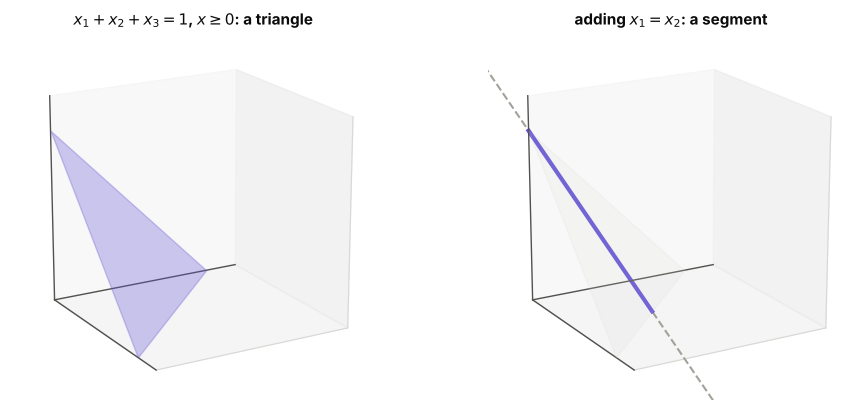

In [2]:

from mpl_toolkits.mplot3d.art3d import Poly3DCollection

fig = plt.figure(figsize=(10, 4.2))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.add_collection3d(Poly3DCollection([np.eye(3)], facecolor=VIOLET, alpha=0.3, edgecolor=VIOLET))
ax.set_title("$x_1 + x_2 + x_3 = 1$, $x \\geq 0$: a triangle")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
# line: x1 + x2 + x3 = 1 and x1 - x2 = 0  ->  x = (t, t, 1 - 2t), feasible for 0 <= t <= 1/2
t = np.linspace(-0.3, 0.8, 2)
ax2.plot(t, t, 1 - 2 * t, color=FAINT, lw=1.5, ls="--")
ts = np.array([0, 0.5])
ax2.plot(ts, ts, 1 - 2 * ts, color=VIOLET, lw=3, label="feasible segment")
ax2.add_collection3d(Poly3DCollection([np.eye(3)], facecolor=GRID, alpha=0.15, edgecolor=GRID))
ax2.set_title("adding $x_1 = x_2$: a segment")
for a in (ax, ax2):
    for i in range(3):
        a.plot(*np.c_[np.zeros(3), 1.2 * np.eye(3)[i]], color=MUTED, lw=1)
    a.set_xlim(0, 1.2); a.set_ylim(0, 1.2); a.set_zlim(0, 1.2); a.set_box_aspect((1, 1, 1))
    a.set_xticks([]); a.set_yticks([]); a.set_zticks([]); a.view_init(elev=18, azim=-30)
plt.tight_layout(); plt.show()


## 3\. Standing Assumptions

::: {#prp-independent-rows}
## Redundant Equations Can Be Removed

Suppose $Ax = b$ has a solution, and let the rows $a_i^{\mathsf T}$, $i \in I$, form a basis of the row space of $A$. Then $\{x : Ax = b\} = \{x : a_i^{\mathsf T}x = b_i,\ i \in I\}$.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-independent-rows
"$\subseteq$" is clear. Let $x_0$ solve $Ax = b$. Each row is a combination $a_k = \sum_{i \in I}\lambda_{ki}a_i$, so $b_k = a_k^{\mathsf T}x_0 = \sum_i \lambda_{ki}a_i^{\mathsf T}x_0 = \sum_i\lambda_{ki}b_i$. If $a_i^{\mathsf T}x = b_i$ for $i \in I$, then $a_k^{\mathsf T}x = \sum_i\lambda_{ki}b_i = b_k$ for every $k$. $\blacksquare$
:::

Whether $Ax = b$ is solvable, and a basis of the row space, can be found by Gaussian elimination. If $Ax = b$ has no solution, the LP is infeasible. Hence, from now on, for LPs in equational form we assume:

1. $Ax = b$ has at least one solution;
2. the rows of $A$ are linearly independent, i.e. $\operatorname{rank} A = m$.

Then $m \le n$ ($m$ independent vectors in $\mathbb{R}^n$), and the columns of $A$ span $\mathbb{R}^m$ (column rank $=$ row rank $= m$). Assumption 1 does not mean that the LP is feasible: the affine subspace $\{Ax = b\}$ may miss the orthant.